In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
results = pd.read_csv("/n/holylfs05/LABS/arguelles_delgado_lab/Everyone/jbook/double_cascade_identification/training_output/new_MC/L3/dynedge_dbang_decay_length/MAEloss_training_results.csv")

Text(0.5, 1.0, 'L3 files')

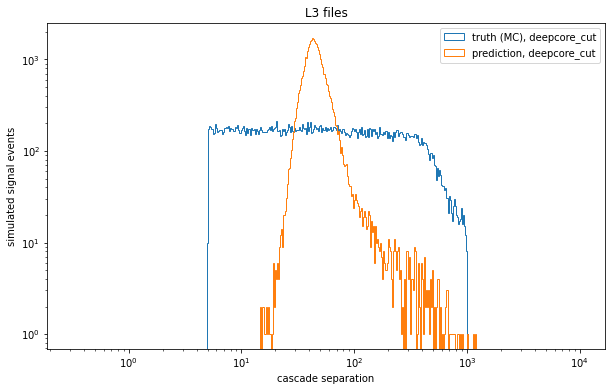

In [6]:
plt.figure(figsize=(10, 6))
bins = np.logspace(-0.5, 4, 500)

plt.hist(results['dbang_decay_length'], histtype="step", bins=bins, label="truth (MC), deepcore_cut")
plt.hist(results['dbang_decay_length_pred'], histtype="step", bins=bins, label="prediction, deepcore_cut")


plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.xlabel('cascade separation')
plt.ylabel('simulated signal events')
# plt.xlabel("Energy(GeV)")
plt.title("L3 files")

Two figures to work towards: 
Classification score for signal vs background


Text(0.5, 1.0, 'Cascade separation, HNL only')

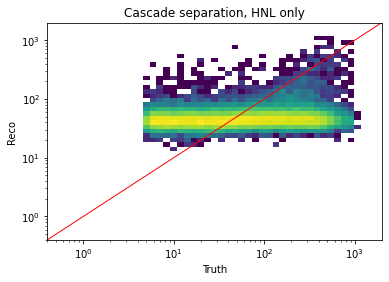

In [9]:
from matplotlib import colors

bins = np.logspace(-0.4, 3.3, 50)
plt.hist2d(results['dbang_decay_length'],results['dbang_decay_length_pred'], bins=bins, norm=colors.LogNorm())
# Add a line 
plt.plot([-2, 2000], [-2, 2000], color='red', linestyle='-', linewidth=1)

plt.xscale('log')
plt.yscale('log')

plt.xlabel("Truth")
plt.ylabel("Reco")
plt.title("Cascade separation, HNL only")

# plt.colorbar()

In [24]:
longer_results.head()
good_reco_mask = np.abs(longer_results['dbang_decay_length_pred']- longer_results['dbang_decay_length'])/longer_results['dbang_decay_length']<0.1

In [26]:
longer_results.head()

,Unnamed: 0,dbang_decay_length_pred,dbang_decay_length,pid,energy,event_weight,azimuth,zenith,event_no
0,0,65.273300,80.592375,19.0,49.411306,6.395898e-15,2.342150,2.220942,0.0
1,1,14.505924,19.179646,19.0,18.538009,1.698418e-14,3.966716,2.226325,1.0
2,2,11.515635,12.140926,19.0,147.594729,4.059710e-17,1.554518,1.927149,2.0
3,3,68.306313,134.429503,19.0,4720.280472,2.016766e-21,1.095889,2.803243,4.0
4,4,292.332367,221.923152,19.0,40.847561,2.978214e-15,5.073490,1.700984,5.0


Text(0.5, 0, 'Energy(GeV)')

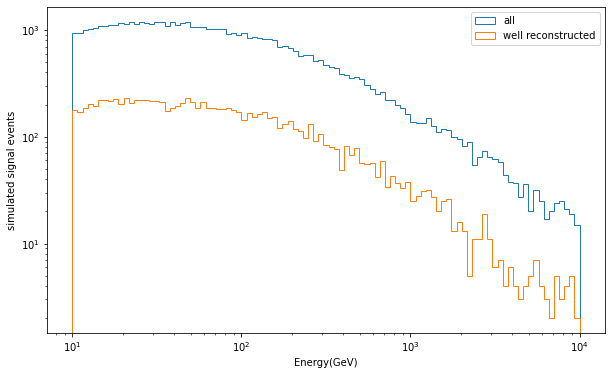

In [30]:
plt.figure(figsize=(10, 6))
bins = np.logspace(1, 4, 100)

plt.hist(longer_results['energy'], histtype="step", bins=bins, label="all")
plt.hist(longer_results[good_reco_mask]['energy'], histtype="step", bins=bins, label="well reconstructed")

plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.ylabel('simulated signal events')
plt.xlabel("Energy(GeV)")

Text(0.5, 0, 'Zenith angle (degrees)')

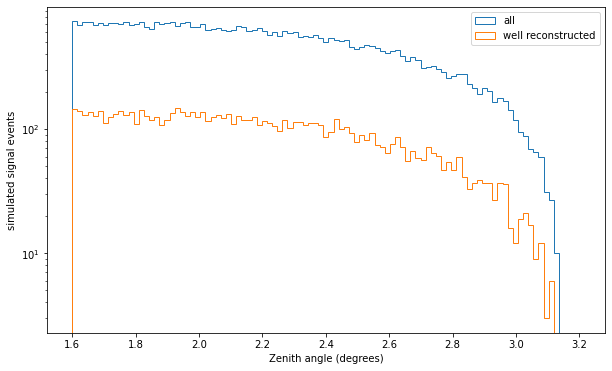

In [34]:
plt.figure(figsize=(10, 6))
bins = np.linspace(1.6, 3.2, 100)

plt.hist(longer_results['zenith'], histtype="step", bins=bins, label="all")
plt.hist(longer_results[good_reco_mask]['zenith'], histtype="step", bins=bins, label="well reconstructed")

# plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.ylabel('simulated signal events')
plt.xlabel("Zenith angle (degrees)")

Text(0.5, 0, 'Azimuth angle (degrees)')

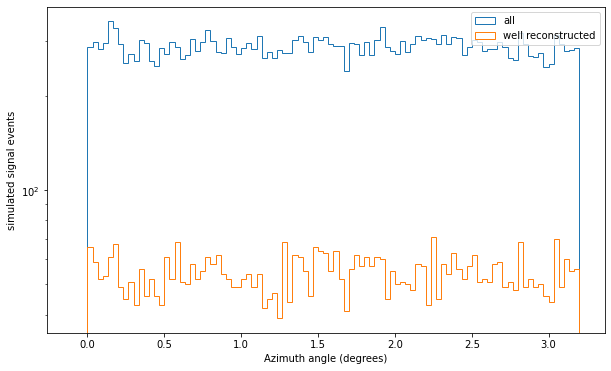

In [37]:
plt.figure(figsize=(10, 6))
bins = np.linspace(-0.1, 3.2, 100)

plt.hist(longer_results['azimuth'], histtype="step", bins=bins, label="all")
plt.hist(longer_results[good_reco_mask]['azimuth'], histtype="step", bins=bins, label="well reconstructed")

# plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.ylabel('simulated signal events')
plt.xlabel("Azimuth angle (degrees)")

Text(0.5, 0, 'Event Weight (LetonInjector+decay length correction)')

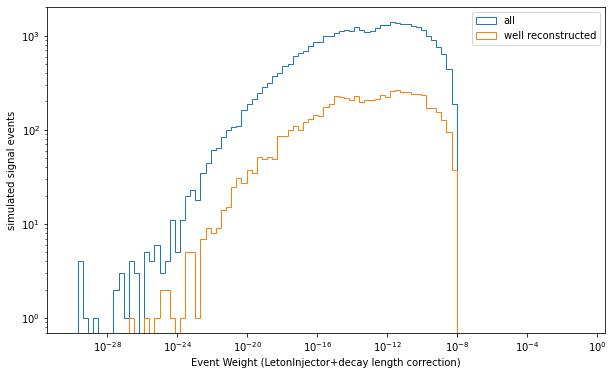

In [42]:
plt.figure(figsize=(10, 6))
bins = np.logspace(-30, -1, 100)

plt.hist(longer_results['event_weight'], histtype="step", bins=bins, label="all")
plt.hist(longer_results[good_reco_mask]['event_weight'], histtype="step", bins=bins, label="well reconstructed")

plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.ylabel('simulated signal events')
plt.xlabel("Event Weight (LetonInjector+decay length correction)")

In [ ]:
### bins = np.logspace(0, 3.5, 50)
energy_mask = results_1m['energy']>00.0
plt.hist2d(results_1m[energy_mask]['dbang_decay_length'],results_1m[energy_mask]['dbang_decay_length_pred'], bins=bins, norm=colors.LogNorm())

plt.xscale('log')
plt.yscale('log')

plt.xlabel("Truth")
plt.ylabel("Reco")
plt.title("Cascade separation, HNL only, 1m min separation")

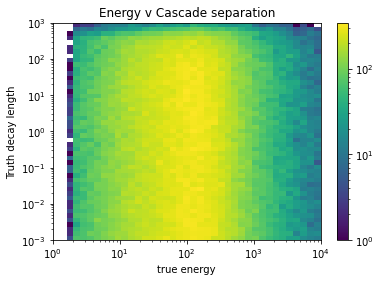

In [8]:
ybins = np.logspace(-3, 3, 50)
xbins = np.logspace(0, 4, 40)
plt.hist2d(results['energy'], results['dbang_decay_length'], bins=[xbins, ybins], norm=colors.LogNorm())

plt.xscale('log')
plt.yscale('log')

plt.ylabel("Truth decay length")
plt.xlabel("true energy")
plt.title("Energy v Cascade separation")

plt.colorbar()

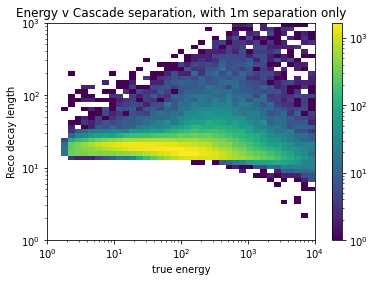

In [23]:
ybins = np.logspace(0, 3, 50)
xbins = np.logspace(0, 4, 40)
plt.hist2d(results_1m['energy'], results_1m['dbang_decay_length_pred'], bins=[xbins, ybins], norm=colors.LogNorm())

plt.xscale('log')
plt.yscale('log')

plt.ylabel("Reco decay length")
plt.xlabel("true energy")
plt.title("Energy v Cascade separation, with 1m separation only")

plt.colorbar()

### Hypothesis:
What if we only train on higher energy events? It looks like we may have a lot more potential over 100 GeV. That being said, I think it's time to move one to a classifier for now.

That is, after adding layers as Carlos suggested.